# **Лабораторна робота №1 “Multilayer Perceptron from scratch”**
**Виконав студент групи КН-31, Бенза Р. А.**

## **1. Завантаження та огляд даних**

Спочатку підключимо необхідні бібліотеки та задамо основні параметри експерименту. Далі завантажимо навчальний і тестовий датасети та переглянемо їхню розмірність.

In [24]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

SEED, EPOCHS = 42, 60
HIDDEN = (32,)          # розміри прихованих шарів; (32,) = один шар, (32, 16) = два тощо
SEEDS = [0, 1, 2]       # кілька ініціалізацій для надійного порівняння активацій
rng = np.random.default_rng(SEED)

Файли читаємо за допомогою `np.genfromtxt` (без `pandas`). Колонки `id` та `smoking` не є ознаками, тому відокремлюємо їх від матриці ознак `X`.

In [25]:
def load_csv(path):
    header = open(path).readline().strip().split(",")
    return header, np.genfromtxt(path, delimiter=",", skip_header=1)

hdr, train = load_csv("lab-1/data/train.csv")
hdr_te, test = load_csv("lab-1/data/test.csv")

features = [h for h in hdr if h not in ("id", "smoking")]
X_all = train[:, [hdr.index(h) for h in features]]
y_all = train[:, hdr.index("smoking")].reshape(-1, 1)
X_test = test[:, [hdr_te.index(h) for h in features]]
test_ids = test[:, hdr_te.index("id")].astype(int)
print("train:", X_all.shape, "| test:", X_test.shape, "| positive rate:", round(y_all.mean(), 4))

train: (15000, 22) | test: (10000, 22) | positive rate: 0.3672


Навчальний набір містить 15 000 записів, тестовий — 10 000, кожен запис описується 22 ознаками. Частка курців у навчальній вибірці становить близько 37%, тобто класи помірно незбалансовані.

## **2. Дослідження та візуалізація даних**

Для початку виведемо описову статистику кожної ознаки та перевіримо наявність пропущених значень.

In [26]:
# Описова статистика та перевірка пропусків
print(f"{'feature':22s}{'mean':>10s}{'std':>10s}{'min':>10s}{'max':>10s}")
for j, f in enumerate(features):
    c = X_all[:, j]
    print(f"{f:22s}{c.mean():10.2f}{c.std():10.2f}{c.min():10.2f}{c.max():10.2f}")
print("\nПропуски (NaN): train =", int(np.isnan(X_all).sum()), "| test =", int(np.isnan(X_test).sum()))

feature                     mean       std       min       max
age                        42.73     10.57     20.00     85.00
height(cm)                164.68      8.60    140.00    190.00
weight(kg)                 64.29     10.98     35.00    115.00
waist(cm)                  80.29      7.91     57.00    116.20
eyesight(left)              1.03      0.31      0.10      9.90
eyesight(right)             1.02      0.29      0.10      9.90
hearing(left)               1.01      0.08      1.00      2.00
hearing(right)              1.00      0.07      1.00      2.00
systolic                  119.20     11.17     60.00    178.00
relaxation                 74.89      7.92     47.00    108.00
fasting blood sugar        95.10     10.26     64.00    274.00
Cholesterol               191.32     20.47    115.00    297.00
triglyceride              102.13     47.23     18.00    399.00
HDL                        57.37     11.42     28.00    112.00
LDL                       113.46     18.68     32.00   

Пропущених значень немає, тож додаткова обробка не потрібна.
Далі побудуємо розподіл класів і подивимось, наскільки сильно кожна ознака корелює з цільовою змінною `smoking`.

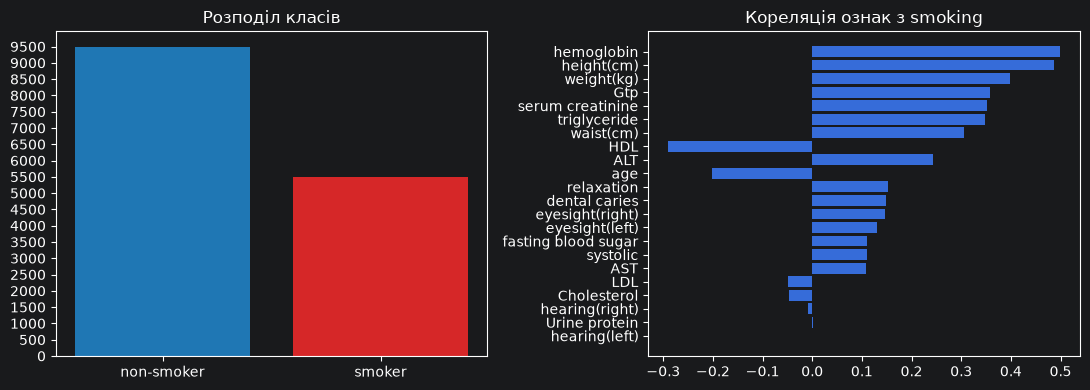

In [27]:
corr = np.array([np.corrcoef(X_all[:, j], y_all[:, 0])[0, 1] for j in range(len(features))])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
class_counts = [(y_all == 0).sum(), (y_all == 1).sum()]
ax[0].bar(["non-smoker", "smoker"], class_counts, color=["tab:blue", "tab:red"])
ax[0].set_yticks(np.arange(0, max(class_counts) + 501, 500))
ax[0].set_title("Розподіл класів")
order = np.argsort(np.abs(corr))
ax[1].barh(np.array(features)[order], corr[order])
ax[1].set_title("Кореляція ознак з smoking")
plt.tight_layout(); plt.show()

Найсильніше з курінням пов’язані `hemoglobin`, `height(cm)`, `weight(kg)` та `Gtp`. Порівняємо розподіли 8 найбільш корельованих ознак окремо для курців і некурців:

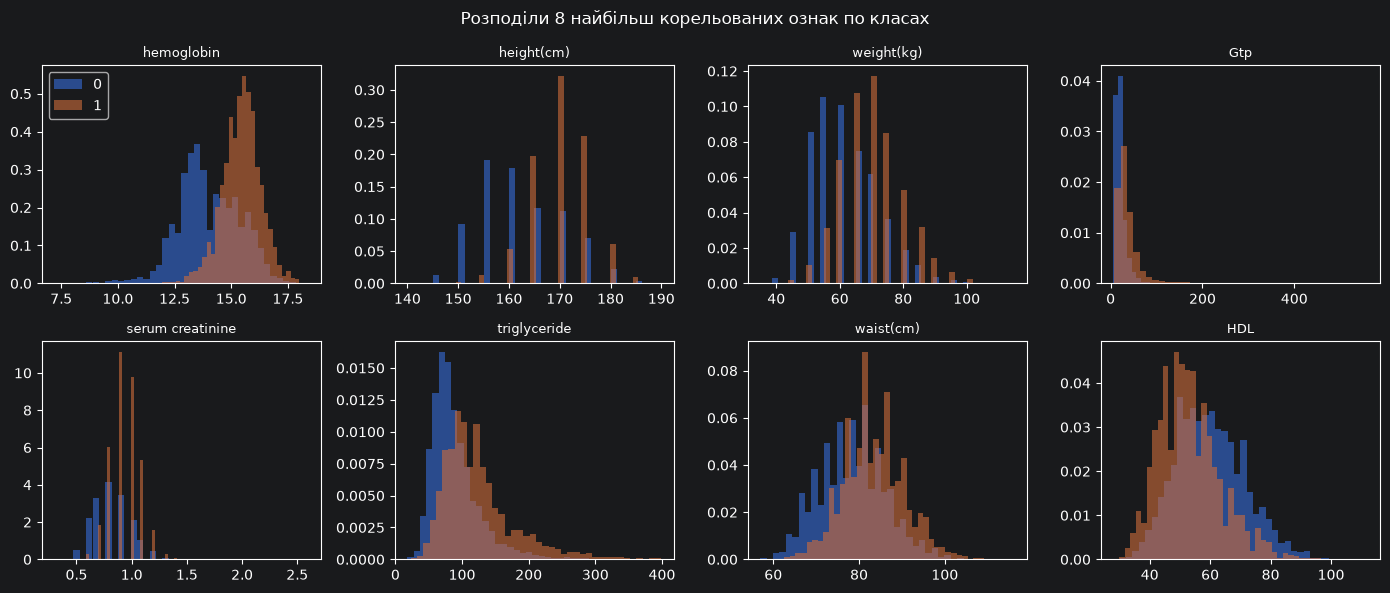

In [28]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for a, j in zip(axs.ravel(), np.argsort(-np.abs(corr))[:8]):
    for c in (0, 1):
        a.hist(X_all[y_all[:, 0] == c, j], bins=40, alpha=0.6, density=True, label=str(c))
    a.set_title(features[j], fontsize=9)
axs[0, 0].legend()
plt.suptitle("Розподіли 8 найбільш корельованих ознак по класах")
plt.tight_layout(); plt.show()

Розподіли для двох класів помітно зміщені, але значно перекриваються, тому очікувати ідеального розділення не варто. Нарешті, подивимось на кореляції між самими ознаками:

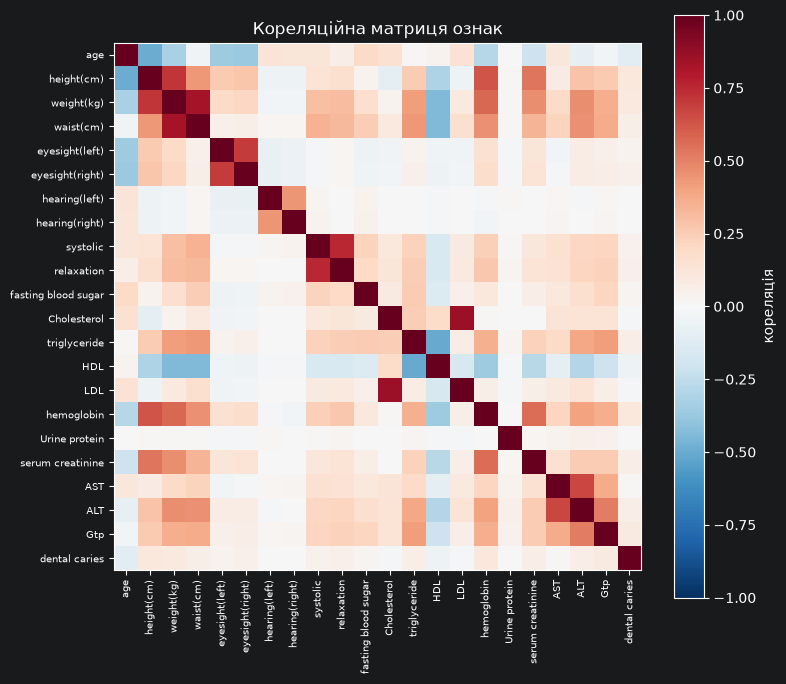

In [29]:
plt.figure(figsize=(8, 7))
plt.imshow(np.corrcoef(X_all.T), cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="кореляція")
plt.xticks(range(len(features)), features, rotation=90, fontsize=7)
plt.yticks(range(len(features)), features, fontsize=7)
plt.title("Кореляційна матриця ознак")
plt.tight_layout(); plt.show()

На матриці видно групи взаємопов’язаних ознак (наприклад, зріст, вага та об’єм талії; `Cholesterol` та `LDL`), що є звичайним для медичних даних. Далі підготуємо дані для навчання моделі.

## **3. Підготовка даних**

Нейронні мережі чутливі до масштабу ознак, тому виконаємо стандартизацію: від кожної ознаки віднімаємо середнє та ділимо на стандартне відхилення. Додатково обрізаємо значення за межами $[-5, 5]$, щоб послабити вплив викидів. Параметри стандартизації обчислюємо **лише за навчальною частиною**, щоб уникнути витоку інформації з валідаційної вибірки.

Для оцінки якості під час експериментів виділимо 20% навчальних даних у валідаційну вибірку.

In [30]:
perm = rng.permutation(len(X_all))
n_val = len(X_all) // 5
va, tr = perm[:n_val], perm[n_val:]

mu, sd = X_all[tr].mean(0), X_all[tr].std(0) + 1e-9
preprocess = lambda X: np.clip((X - mu) / sd, -5, 5)   # стандартизація + обрізання викидів

Xtr, ytr = preprocess(X_all[tr]), y_all[tr]
Xva, yva = preprocess(X_all[va]), y_all[va]

Для оцінювання якості моделі використаємо три метрики:

- **Binary Cross-Entropy (BCE)** — функція втрат, яку мінімізує навчання;
- **Accuracy** — частка правильно класифікованих прикладів при порозі 0.5;
- **ROC AUC** — основна метрика змагання. Її обчислюємо вручну через ранги за статистикою Манна–Вітні:

$$
\mathrm{AUC} = \frac{\sum\limits_{i \in \text{pos}} r_i - \frac{n_+ (n_+ + 1)}{2}}{n_+ \, n_-}
$$

де:

- $r_i$ — ранг оцінки $i$-го позитивного прикладу серед усіх прикладів;
- $n_+$ та $n_-$ — кількість позитивних і негативних прикладів.

In [31]:
def roc_auc(y, scores):
    """AUC через ранги (Mann–Whitney U)."""
    y = y.ravel() > 0.5
    ranks = scores.ravel().argsort().argsort() + 1
    n_pos, n_neg = y.sum(), (~y).sum()
    return (ranks[y].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def accuracy(y, p):
    return np.mean((p > 0.5) == (y > 0.5))

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

## **4. Побудова нейронної мережі**

### **4a. Функції активації**

Нелінійність мережі забезпечують функції активації $g(z)$. Для кожної з них потрібно знати не лише саму функцію, а й її похідну, яка використовується під час зворотного поширення:

| Активація | $g(z)$ | $g'(z)$ |
|---|---|---|
| Sigmoid | $\sigma(z)=\frac{1}{1+e^{-z}}$ | $\sigma(z)\,(1-\sigma(z))$ |
| Tanh | $\tanh z$ | $1-\tanh^2 z$ |
| ReLU | $\max(0,z)$ | $1$ при $z>0$, інакше $0$ |
| Swish (для порівняння) | $z\,\sigma(z)$ | $\sigma(z)+z\,\sigma(z)(1-\sigma(z))$ |
| **tanh+linear (власна)** | $\tanh z + 0.1\,z$ | $1-\tanh^2 z + 0.1$ |

**Ідея власної функції.** Звичайний tanh насичується при великих $|z|$, і його градієнт прямує до нуля. Додавання лінійного доданка $0.1z$ зберігає гладкість і нелінійність tanh, але гарантує, що похідна завжди не менша за $0.1$, тобто градієнт повністю не зникає.

In [32]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -50, 50)))

# назва: (функція, її похідна)
ACTIVATIONS = {
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":    (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
    "relu":    (lambda z: np.maximum(0, z), lambda z: (z > 0).astype(float)),
    "swish":   (lambda z: z * sigmoid(z),
                lambda z: sigmoid(z) + z * sigmoid(z) * (1 - sigmoid(z))),
    # ВЛАСНА активація: tanh з лінійним доданком (не насичується повністю)
    "tanh+linear (custom)": (lambda z: np.tanh(z) + 0.1 * z,
                             lambda z: 1 - np.tanh(z) ** 2 + 0.1),
}

Побудуємо графіки функцій та їхніх похідних, щоб побачити різницю між ними:

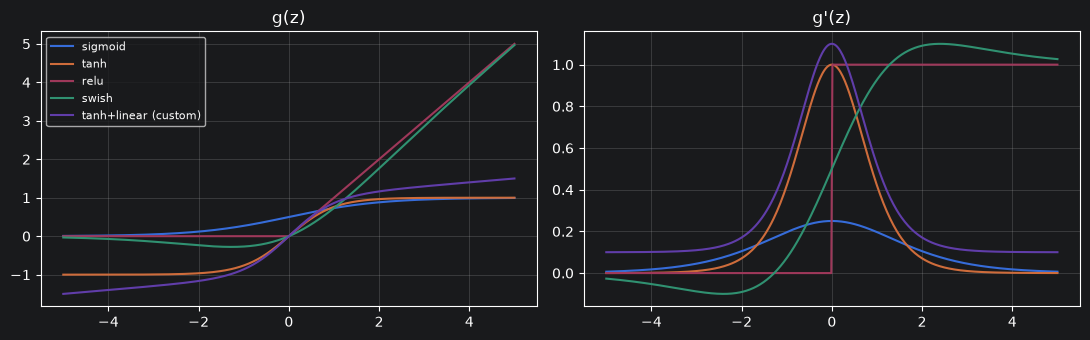

In [33]:
z = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, (f, df) in ACTIVATIONS.items():
    ax[0].plot(z, f(z), label=name); ax[1].plot(z, df(z), label=name)
ax[0].set_title("g(z)"); ax[1].set_title("g'(z)"); ax[0].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Видно, що похідна sigmoid не перевищує 0.25 та швидко затухає, похідна tanh досягає 1 лише поблизу нуля, а ReLU та Swish не насичуються при додатних $z$. Похідна власної функції ніколи не опускається нижче 0.1.

### **4b. Прямий прохід та функція втрат**

Мережа складається з $L$ шарів. Нехай $A^{[0]} = X$, тоді для $l = 1, \dots, L$:

$$
Z^{[l]} = A^{[l-1]} W^{[l]} + b^{[l]}
$$
$$
A^{[l]} = g\big(Z^{[l]}\big) \quad (l < L), \qquad A^{[L]} = \sigma\big(Z^{[L]}\big) = \hat{y}
$$

де:

- $W^{[l]}$ та $b^{[l]}$ — матриця ваг та вектор зсувів $l$-го шару;
- $g$ — функція активації прихованих шарів;
- $\hat{y}$ — передбачена ймовірність того, що людина курить.

Для оцінки якості прогнозів використовується функція втрат Binary Cross-Entropy на батчі з $m$ прикладів:

$$
\mathcal{L} = -\frac{1}{m} \sum\limits_{i=1}^{m} \Big[ y_i \ln \hat{y}_i + (1 - y_i) \ln (1 - \hat{y}_i) \Big]
$$

### **4c. Зворотне поширення помилки (backpropagation)**

Щоб навчити мережу, потрібно знайти градієнти функції втрат за всіма параметрами. Скористаємось ланцюговим правилом, рухаючись від виходу мережі до входу.

**Крок 1 — вихідний шар.** Похідна функції втрат за виходом:

$$
\frac{\partial \mathcal{L}}{\partial \hat{y}_i} = -\frac{1}{m} \left( \frac{y_i}{\hat{y}_i} - \frac{1 - y_i}{1 - \hat{y}_i} \right) = \frac{\hat{y}_i - y_i}{m \, \hat{y}_i (1 - \hat{y}_i)}
$$

Оскільки $\sigma'(z) = \hat{y}(1 - \hat{y})$, множники $\hat{y}(1 - \hat{y})$ скорочуються, і отримуємо просту формулу:

$$
dZ^{[L]} = \frac{\hat{y} - y}{m}
$$

**Крок 2 — градієнти параметрів $l$-го шару:**

$$
dW^{[l]} = \big(A^{[l-1]}\big)^{\top} dZ^{[l]} \\
$$
$$
db^{[l]} = \sum\limits_{\text{рядки}} dZ^{[l]}
$$

**Крок 3 — перехід до попереднього шару:**

$$
dA^{[l-1]} = dZ^{[l]} \big(W^{[l]}\big)^{\top} \\
$$
$$
dZ^{[l-1]} = dA^{[l-1]} \odot g'\big(Z^{[l-1]}\big)
$$

де $\odot$ — поелементне множення. Кроки 2 і 3 повторюються для $l = L, L-1, \dots, 1$.

**Крок 4 — оновлення ваг.** Для швидкості навчання $\alpha$ використаємо два правила:

- звичайний градієнтний спуск (SGD):

$$
W = W - \alpha \, dW
$$

- Adam, який використовує згладжені моменти градієнта:

$$
m = \beta_1 m + (1 - \beta_1)\, dW, \qquad v = \beta_2 v + (1 - \beta_2)\, dW^2
$$
$$
W = W - \alpha \, \frac{m / (1 - \beta_1^t)}{\sqrt{v / (1 - \beta_2^t)} + \varepsilon}
$$

Реалізуємо ці формули у вигляді класу `MLP`. Кількість прихованих шарів задається параметром `hidden`, а правило оновлення ваг — параметром `opt`.

In [34]:
class MLP:
    """Повнозв'язна мережа: input -> [Dense -> g] x len(hidden) -> Dense(1) -> sigmoid."""

    def __init__(self, n_in, hidden=HIDDEN, activation="relu", seed=SEED):
        r = np.random.default_rng(seed)
        self.act, self.dact = ACTIVATIONS[activation]
        sizes = [n_in, *hidden, 1]
        self.L = len(sizes) - 1
        self.p = {}
        for l in range(1, self.L + 1):
            gain = 2 if (activation == "relu" and l < self.L) else 1     # He / Xavier-подібна ініціалізація
            self.p[f"W{l}"] = r.normal(0, np.sqrt(gain / sizes[l - 1]), (sizes[l - 1], sizes[l]))
            self.p[f"b{l}"] = np.zeros((1, sizes[l]))
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}   # Adam: 1-й момент
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}   # Adam: 2-й момент
        self.t = 0

    def forward(self, X):
        cache = [(None, X)]                                  # cache[l] = (Z^[l], A^[l])
        A = X
        for l in range(1, self.L + 1):
            Z = A @ self.p[f"W{l}"] + self.p[f"b{l}"]
            A = sigmoid(Z) if l == self.L else self.act(Z)
            cache.append((Z, A))
        return A, cache

    def predict(self, X):
        return self.forward(X)[0]

    def backward(self, y, cache):
        grads = {}
        dZ = (cache[-1][1] - y) / len(y)                     # dZ^[L] = (y_hat - y) / m
        for l in range(self.L, 0, -1):
            grads[f"W{l}"] = cache[l - 1][1].T @ dZ          # dW = A_prev^T dZ
            grads[f"b{l}"] = dZ.sum(0, keepdims=True)        # db = sum(dZ)
            if l > 1:                                        # dZ^[l-1] = (dZ W^T) * g'(Z^[l-1])
                dZ = (dZ @ self.p[f"W{l}"].T) * self.dact(cache[l - 1][0])
        return grads

    def step(self, grads, lr, opt="adam", b1=0.9, b2=0.999, eps=1e-8):
        if opt == "sgd":
            for k, g in grads.items():
                self.p[k] -= lr * g
            return
        self.t += 1
        for k, g in grads.items():
            self.m[k] = b1 * self.m[k] + (1 - b1) * g
            self.v[k] = b2 * self.v[k] + (1 - b2) * g ** 2
            m_hat = self.m[k] / (1 - b1 ** self.t)
            v_hat = self.v[k] / (1 - b2 ** self.t)
            self.p[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)

    def fit(self, X, y, Xv=None, yv=None, epochs=30, lr=1e-3, batch=1024, opt="adam"):
        hist = {"train_loss": [], "val_loss": [], "val_auc": [], "val_acc": []}
        for _ in range(epochs):
            idx = rng.permutation(len(X))
            for s in range(0, len(X), batch):
                b = idx[s:s + batch]
                self.step(self.backward(y[b], self.forward(X[b])[1]), lr, opt)
            hist["train_loss"].append(bce(y, self.predict(X)))
            if Xv is not None:
                pv = self.predict(Xv)
                hist["val_loss"].append(bce(yv, pv))
                hist["val_auc"].append(roc_auc(yv, pv))
                hist["val_acc"].append(accuracy(yv, pv))
        return hist

## **5. Навчання та експерименти**

### **5a. Перевірка коректності градієнтів**

Перед навчанням переконаємось, що backpropagation реалізований правильно. Для цього порівняємо аналітичні градієнти з числовими, обчисленими методом центральних різниць:

$$
\frac{\partial \mathcal{L}}{\partial w} \approx \frac{\mathcal{L}(w + \varepsilon) - \mathcal{L}(w - \varepsilon)}{2 \varepsilon}
$$

Перевірку виконаємо для всіх активацій, для мережі з одним та двома прихованими шарами.

In [35]:
def gradient_check(activation, hidden):
    r = np.random.default_rng(0)
    net = MLP(6, hidden, activation, seed=1)
    X, y = r.normal(size=(20, 6)), (r.random((20, 1)) > 0.5).astype(float)
    ana = net.backward(y, net.forward(X)[1])
    worst = 0
    for k, W in net.p.items():
        num = np.zeros_like(W)
        for i in np.ndindex(W.shape):
            old = W[i]
            W[i] = old + 1e-5; lp = bce(y, net.predict(X))
            W[i] = old - 1e-5; lm = bce(y, net.predict(X))
            W[i] = old
            num[i] = (lp - lm) / 2e-5
        worst = max(worst, np.linalg.norm(ana[k] - num) / (np.linalg.norm(ana[k]) + np.linalg.norm(num) + 1e-12))
    return worst

print(f"{'activation':24s}{'1 шар':>12s}{'2 шари':>12s}     (має бути < 1e-6)")
for name in ACTIVATIONS:
    print(f"{name:24s}{gradient_check(name, (5,)):12.2e}{gradient_check(name, (5, 4)):12.2e}")

activation                     1 шар      2 шари     (має бути < 1e-6)
sigmoid                     3.69e-10    7.84e-09
tanh                        5.26e-11    4.46e-10
relu                        9.03e-11    2.99e-10
swish                       1.56e-10    9.93e-10
tanh+linear (custom)        1.02e-10    3.40e-10


Відносна похибка для всіх активацій та обох архітектур набагато менша за $10^{-6}$, отже, зворотне поширення помилки реалізоване коректно.

### **5b. Порівняння функцій активації**

Тепер порівняємо активації. Щоб різниця між ними не була випадковою, кожну навчимо з трьома різними ініціалізаціями ваг (Adam, $\alpha = 0.002$, 60 епох). Збіжність оцінимо кількісно: за кількістю епох, потрібних щоб значення функції втрат на валідації опустилось до 0.42.

In [36]:
THRESH = 0.42
runs, nets = {name: [] for name in ACTIVATIONS}, {}

def epochs_to(h, thr=THRESH):
    hit = np.where(np.array(h["val_loss"]) <= thr)[0]
    return hit[0] + 1 if len(hit) else np.nan

for name in ACTIVATIONS:
    for s in SEEDS:
        net = MLP(Xtr.shape[1], HIDDEN, name, seed=SEED + s)
        runs[name].append(net.fit(Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=2e-3))
        if s == SEEDS[0]:
            nets[name] = net

Виведемо підсумкову таблицю: середні значення метрик та їхнє стандартне відхилення по трьох запусках.

In [37]:
print(f"{'activation':24s}{'val AUC':>16s}{'val acc':>16s}{'val loss':>16s}{'epochs to ' + str(THRESH):>18s}")
for name, hs in runs.items():
    f = lambda k: np.array([h[k][-1] for h in hs])
    ep = np.array([epochs_to(h) for h in hs])
    print(f"{name:24s}{f('val_auc').mean():9.4f} ±{f('val_auc').std():.4f}"
          f"{f('val_acc').mean():9.4f} ±{f('val_acc').std():.4f}"
          f"{f('val_loss').mean():9.4f} ±{f('val_loss').std():.4f}{np.nanmean(ep):14.1f}")

activation                       val AUC         val acc        val loss    epochs to 0.42
sigmoid                    0.8799 ±0.0006   0.7911 ±0.0016   0.4048 ±0.0013          25.3
tanh                       0.8851 ±0.0016   0.8014 ±0.0023   0.3979 ±0.0022          20.3
relu                       0.8877 ±0.0012   0.8038 ±0.0020   0.3934 ±0.0016          11.0
swish                      0.8890 ±0.0010   0.8041 ±0.0014   0.3917 ±0.0016          10.0
tanh+linear (custom)       0.8834 ±0.0019   0.7974 ±0.0027   0.4012 ±0.0023          23.0


Побудуємо також криві навчання (середнє значення та розкид по `seed`):

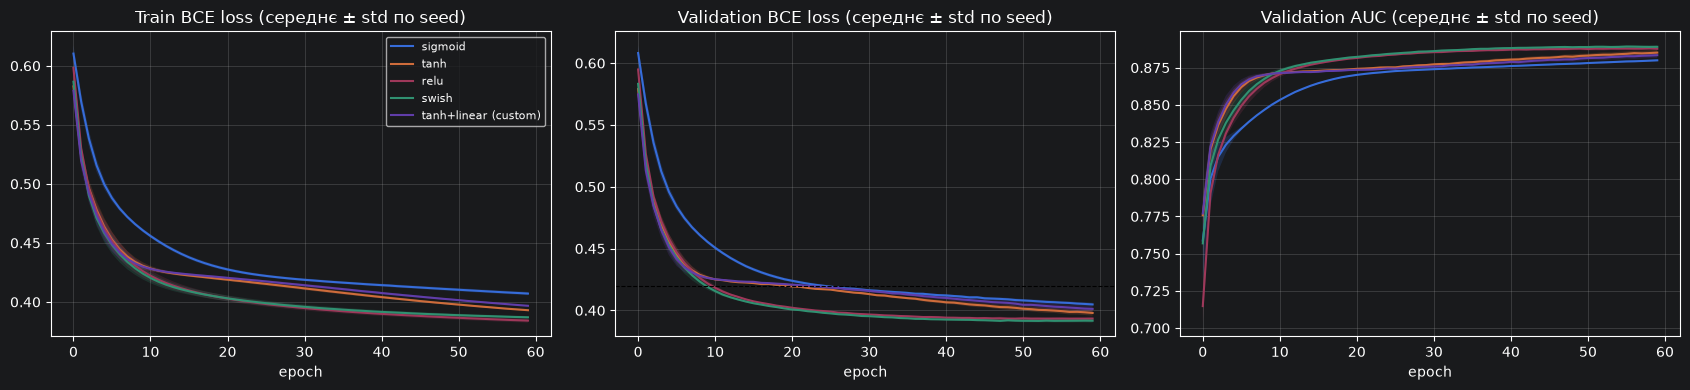

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, key, title in zip(ax, ["train_loss", "val_loss", "val_auc"], ["Train BCE loss", "Validation BCE loss", "Validation AUC"]):
    for name, hs in runs.items():
        arr = np.array([h[key] for h in hs])
        mean, std = arr.mean(0), arr.std(0)
        a.plot(mean, label=name); a.fill_between(range(len(mean)), mean - std, mean + std, alpha=.2)
    a.set_title(title + " (середнє ± std по seed)"); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[1].axhline(THRESH, color="k", ls="--", lw=.8)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Як видно з графіків, ReLU та Swish збігаються приблизно вдвічі швидше за tanh та sigmoid: поріг 0.42 вони досягають приблизно за 10–11 епох проти 20–25. Sigmoid навчається найповільніше, а її кінцевий AUC найнижчий. У tanh AUC швидко зростає на перших епохах, але потім виходить на плато.

Власна функція `tanh+linear` поступилась звичайному tanh як за швидкістю збіжності, так і за AUC, хоча і ненабагато. Тобто гіпотеза про те, що лінійний доданок прискорить навчання, не підтвердилась.

### **5c. SGD проти Adam**

Порівняємо два правила оновлення ваг на одній і тій самій архітектурі (ReLU) з однаковим розміром батча. Для звичайного SGD потрібна значно більша швидкість навчання, тому для нього візьмемо $\alpha = 0.5$, а для Adam — $\alpha = 0.002$.

sgd   val AUC 0.8860 | val acc 0.8053 | val loss 0.3982
adam  val AUC 0.8859 | val acc 0.8020 | val loss 0.3970


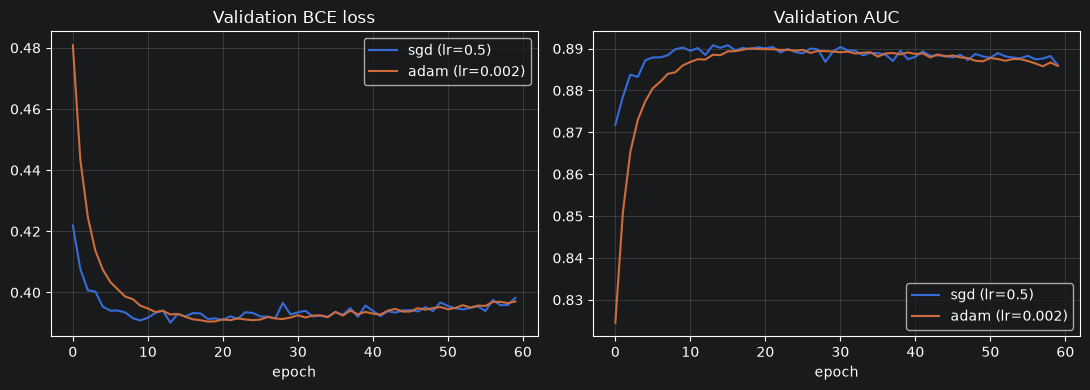

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for opt, lr in [("sgd", 0.5), ("adam", 2e-3)]:
    net = MLP(Xtr.shape[1], HIDDEN, "relu", seed=SEED)
    h = net.fit(Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=lr, batch=256, opt=opt)
    ax[0].plot(h["val_loss"], label=f"{opt} (lr={lr})"); ax[1].plot(h["val_auc"], label=f"{opt} (lr={lr})")
    print(f"{opt:5s} val AUC {h['val_auc'][-1]:.4f} | val acc {h['val_acc'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f}")
ax[0].set_title("Validation BCE loss"); ax[1].set_title("Validation AUC")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

Обидва методи за 60 епох дають практично однаковий результат, але SGD потребує значно більшого кроку навчання, а Adam менш чутливий до цього вибору. Це один запуск, тому висновок орієнтовний.

### **5d. Кількість прихованих шарів**

Архітектура мережі налаштовується параметром `hidden`. Порівняємо мережі з одним, двома та трьома прихованими шарами:

In [40]:
for hidden in [(32,), (32, 16), (64, 32, 16)]:
    net = MLP(Xtr.shape[1], hidden, "relu", seed=SEED)
    h = net.fit(Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=2e-3)
    print(f"hidden={str(hidden):14s} val AUC {h['val_auc'][-1]:.4f} | val acc {h['val_acc'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f}")

hidden=(32,)          val AUC 0.8897 | val acc 0.8040 | val loss 0.3908
hidden=(32, 16)       val AUC 0.8889 | val acc 0.8127 | val loss 0.3927
hidden=(64, 32, 16)   val AUC 0.8682 | val acc 0.7857 | val loss 0.4473


Другий прихований шар не покращив AUC, а три шари дали помітно гірший результат, імовірно через перенавчання або нестабільне навчання без регуляризації. Отже, для цієї задачі достатньо одного прихованого шару.

## **6. Візуалізація меж рішень**

Дані мають 22 виміри, тому для візуалізації спроєктуємо їх на площину двох головних компонент (метод PCA, реалізований через сингулярний розклад). Побудуємо два варіанти:

- **(а)** окрему мережу з двома входами, навчену безпосередньо на цій проєкції;
- **(б)** повну 22-вимірну мережу з розділу 5b, яку зрізаємо площиною PCA (решту компонент приймаємо рівними середньому значенню).

Чорна лінія позначає межу рішень (ймовірність 0.5), колір — ймовірність класу «курець».

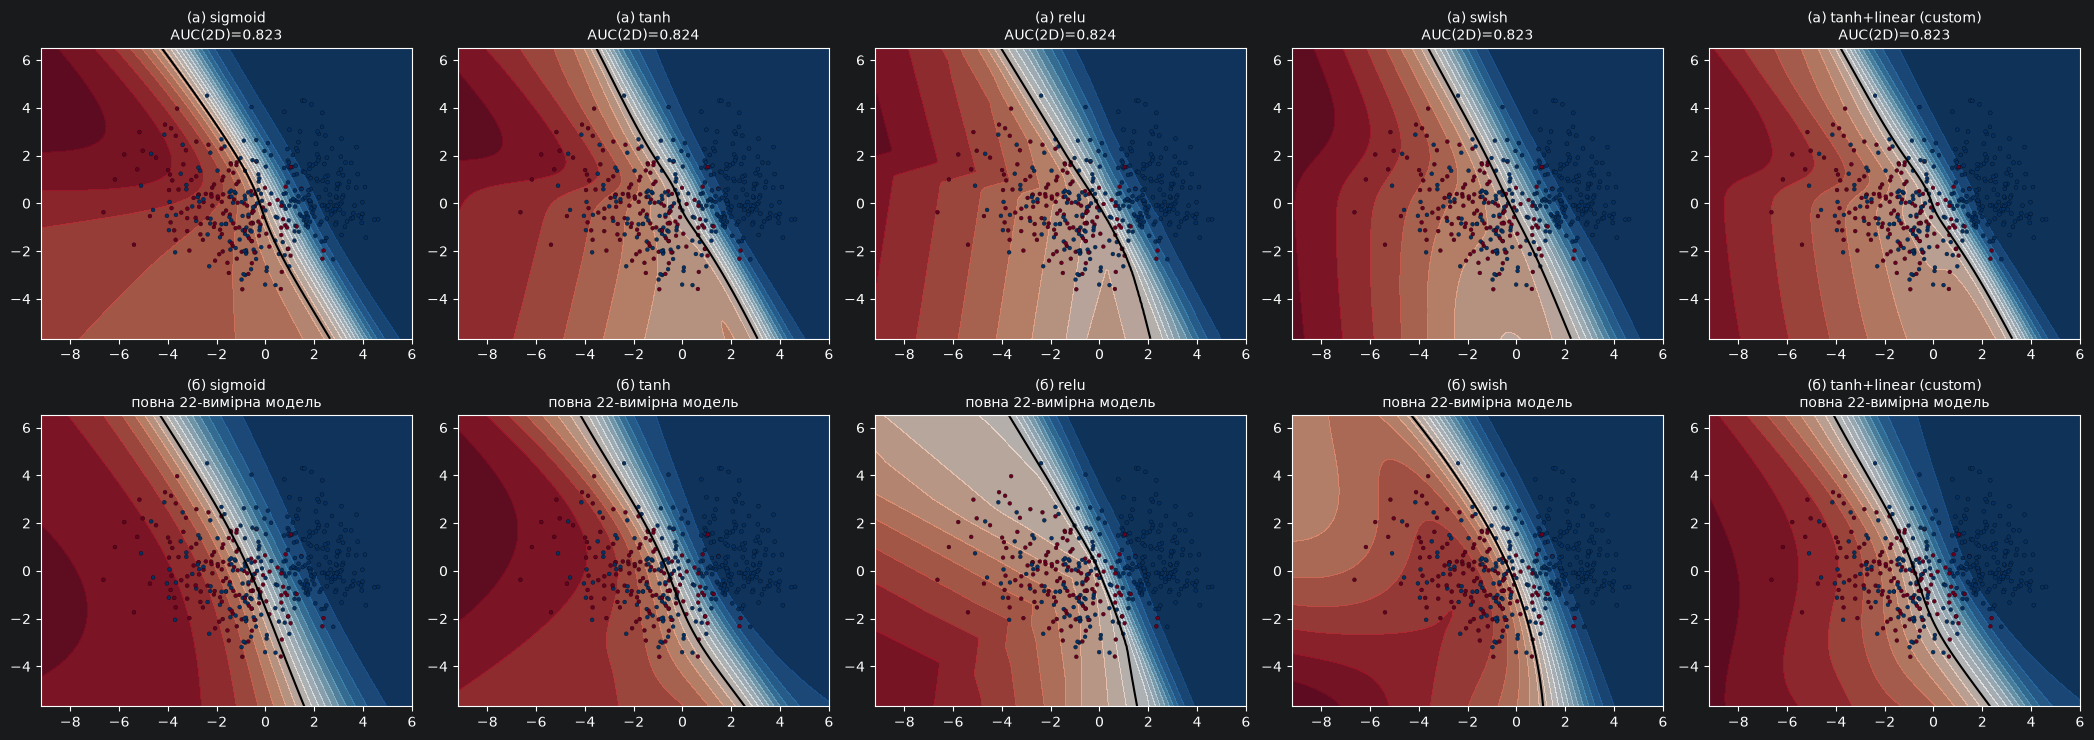

In [41]:
sub = rng.choice(len(Xtr), size=8000, replace=False)
Xs, ys = Xtr[sub], ytr[sub]
x_mean = Xs.mean(0)
_, _, Vt = np.linalg.svd(Xs - x_mean, full_matrices=False)
Z = (Xs - x_mean) @ Vt[:2].T                            # проєкція на 2 головні компоненти

lo, hi = Z.min(0) - .5, Z.max(0) + .5
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 200), np.linspace(lo[1], hi[1], 200))
grid = np.c_[gx.ravel(), gy.ravel()]

def draw(a, pr, title):
    a.contourf(gx, gy, pr.reshape(gx.shape), levels=20, cmap="RdBu_r", alpha=.7)
    a.contour(gx, gy, pr.reshape(gx.shape), levels=[0.5], colors="k")
    a.scatter(Z[:400, 0], Z[:400, 1], c=ys[:400, 0], cmap="RdBu_r", s=8, edgecolor="k", linewidth=.2)
    a.set_title(title, fontsize=10)

n = len(ACTIVATIONS)
fig, axs = plt.subplots(2, n, figsize=(4.2 * n, 7.5))
for j, name in enumerate(ACTIVATIONS):
    net2 = MLP(2, (16,), name)                          # (а) мережа з 2 входами
    net2.fit(Z, ys, epochs=40, lr=5e-3, batch=256)
    draw(axs[0, j], net2.predict(grid), f"(а) {name}\nAUC(2D)={roc_auc(ys, net2.predict(Z)):.3f}")
    full = nets[name]                                   # (б) повна мережа, зріз площиною PCA
    p_full = full.predict(x_mean + grid @ Vt[:2])
    draw(axs[1, j], p_full, f"(б) {name}\nповна 22-вимірна модель")
plt.tight_layout(); plt.show()

У площині двох головних компонент межа рішень близька до лінійної, а класи сильно перекриваються. Тому AUC 2D-моделей (близько 0.82) помітно нижчий, ніж у повної моделі (близько 0.89): частина інформації втрачається при проєкції. Між активаціями відмінності у зоні, де є дані, майже непомітні, вони проявляються переважно на периферії.

## **7. Фінальна модель та submission**

Для фінального прогнозу оберемо активацію з найвищим середнім AUC на валідації та навчимо ансамбль із трьох моделей з різними ініціалізаціями на всіх навчальних даних. Прогнози усереднимо та збережемо у файл `submission.csv`.

In [43]:
best = max(runs, key=lambda k: np.mean([h["val_auc"][-1] for h in runs[k]]))
print("Найкраща активація за середнім val AUC:", best)

mu, sd = X_all.mean(0), X_all.std(0) + 1e-9            # перерахунок препроцесингу на всіх даних
Xf, Xt = preprocess(X_all), preprocess(X_test)
preds = np.zeros(len(Xt))
for s in SEEDS:                                         # ансамбль з 3 ініціалізацій
    net = MLP(Xf.shape[1], HIDDEN, best, seed=SEED + s)
    net.fit(Xf, y_all, epochs=EPOCHS, lr=2e-3)
    preds += net.predict(Xt).ravel() / len(SEEDS)

np.savetxt("lab-1/data/submission.csv", np.c_[test_ids, preds], delimiter=",",
           header="id,smoking", comments="", fmt=["%d", "%.6f"])
print("Збережено submission.csv:", preds.shape, "| min/max:", preds.min().round(3), preds.max().round(3))

Найкраща активація за середнім val AUC: swish
Збережено submission.csv: (10000,) | min/max: 0.0 1.0


Файл `submission.csv` містить колонки `id` та `smoking` (ймовірність від 0 до 1) для всіх записів тестового набору.
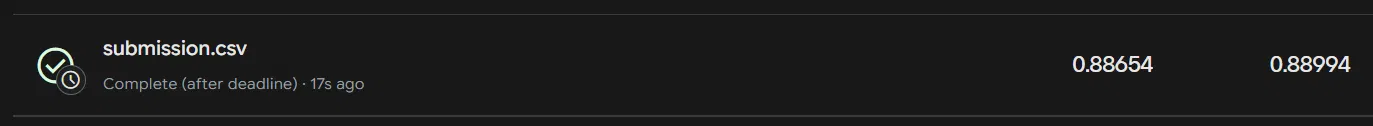

**Висновок:**

У цій лабораторній роботі було з нуля реалізовано багатошаровий перцептрон на `NumPy`: прямий прохід, функцію втрат Binary Cross-Entropy та алгоритм зворотного поширення помилки, коректність якого підтверджена числовою перевіркою градієнтів. Мережу навчено двома способами оновлення ваг — SGD та Adam — і застосовано до задачі передбачення куріння за біосигналами.

Порівняння активацій показало, що ReLU та Swish збігаються найшвидше і дають найкращу якість (val AUC близько 0.888–0.889), tanh займає проміжне положення (0.885), а sigmoid навчається найповільніше й має найнижчий AUC (0.880) через малі значення похідної, які затухають. Власна функція `tanh+linear` не дала переваги над стандартними активаціями (0.883): лінійний доданок не прискорив збіжність. Різниця між ReLU та Swish порівнянна з розкидом результатів між запусками, тому розрізнити їх за цим експериментом неможливо.

Додаткові експерименти показали, що SGD та Adam за 60 епох досягають схожої якості, але Adam менш чутливий до вибору швидкості навчання, а збільшення кількості прихованих шарів для цієї задачі не покращує результат. Візуалізація меж рішень на проєкції PCA демонструє, що класи сильно перекриваються, а повна модель істотно використовує інформацію з усіх 22 ознак.

Водночас порівняння виконано на одному розбитті train/validation з трьома ініціалізаціями, тому різницю порядку 0.001–0.002 AUC слід вважати орієнтовною. Фінальну модель (Swish, ансамбль із трьох ініціалізацій) використано для прогнозу на тестовому наборі, результати збережено у `submission.csv`.